# Этап 4. Классификация (П1–П3)

Цель этапа 4 это час высокого спроса: за час взяли 1000 велосипедов и больше. В такие часы сервису нужно заранее привезти велосипеды на станции. Число аренд `count` в признаки не идёт, из него получена цель. Модель для продукта лежит в `src/train_clf.py`, здесь исследование для П1–П3.

## П1. Цель, стратификация и базовая модель

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, KBinsDiscretizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/clean.csv")
df["high"] = (df["count"] >= 1000).astype(int)
print(df["high"].value_counts(normalize=True).round(3))

num_cols = ["temp", "humidity", "wind", "visibility", "dew_point", "solar", "rainfall", "snowfall"]
cat_cols = ["season", "holiday", "weekend"]
train, test = train_test_split(df, test_size=0.25, random_state=42, stratify=df["high"])
X_train, y_train = train[["hour"] + num_cols + cat_cols], train["high"]
X_test, y_test = test[["hour"] + num_cols + cat_cols], test["high"]
print(train.shape, test.shape, y_train.mean().round(3), y_test.mean().round(3))

high
0    0.714
1    0.286
Name: proportion, dtype: float64
(6348, 14) (2117, 14) 0.286 0.286


In [2]:
prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    (KBinsDiscretizer(n_bins=24, encode="onehot", strategy="uniform"), ["hour"]),
    (make_pipeline(SimpleImputer(strategy="most_frequent"),
                   OneHotEncoder(handle_unknown="ignore")), cat_cols))

for name, clf in [("dummy", DummyClassifier(strategy="most_frequent")),
                  ("logreg", LogisticRegression(max_iter=1000))]:
    m = make_pipeline(prep, clf)
    acc = cross_val_score(m, X_train, y_train, cv=5, scoring="accuracy").mean()
    f1 = cross_val_score(m, X_train, y_train, cv=5, scoring="f1").mean()
    auc = cross_val_score(m, X_train, y_train, cv=5, scoring="roc_auc").mean()
    print(f"{name:7} cv_accuracy {acc:.3f}  cv_f1 {f1:.3f}  cv_auc {auc:.3f}")

dummy   cv_accuracy 0.714  cv_f1 0.000  cv_auc 0.500


logreg  cv_accuracy 0.876  cv_f1 0.787  cv_auc 0.942


**Вывод П1.**
- Часов высокого спроса 28,6 %, классы несбалансированы. Со `stratify` доля класса 1 одинакова в обучении и в тесте, 0,286.
- `DummyClassifier` всегда отвечает «обычный час». Его accuracy 0,714, но F1 = 0 и ROC-AUC = 0,5, он не находит ни одного часа высокого спроса.
- Логистическая регрессия с тем же Pipeline, что на этапе 3 (24 интервала часа), даёт cv_f1 = 0,787 и cv_roc_auc = 0,942. Это базовая модель этапа 4.

## П2. Матрица ошибок

In [3]:
from sklearn.metrics import confusion_matrix, classification_report

model = make_pipeline(prep, LogisticRegression(max_iter=1000)).fit(X_train, y_train)
pred = model.predict(X_test)
cm = confusion_matrix(y_test, pred)
print(cm)
print(classification_report(y_test, pred, digits=3))

tn, fp, fn, tp = cm.ravel()
print("precision вручную", tp, "/", tp + fp, "=", round(tp / (tp + fp), 3))
print("recall вручную   ", tp, "/", tp + fn, "=", round(tp / (tp + fn), 3))

[[1378  134]
 [ 122  483]]
              precision    recall  f1-score   support

           0      0.919     0.911     0.915      1512
           1      0.783     0.798     0.791       605

    accuracy                          0.879      2117
   macro avg      0.851     0.855     0.853      2117
weighted avg      0.880     0.879     0.879      2117

precision вручную 483 / 617 = 0.783
recall вручную    483 / 605 = 0.798


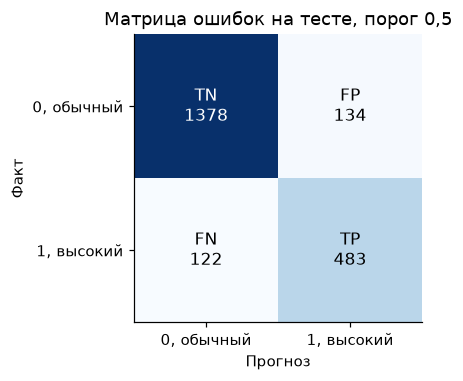

In [4]:
fig, ax = plt.subplots(figsize=(4, 3.4))
ax.imshow(cm, cmap="Blues")
labels = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
ax.set_xticks([0, 1], ["0, обычный", "1, высокий"])
ax.set_yticks([0, 1], ["0, обычный", "1, высокий"])
ax.set_xlabel("Прогноз")
ax.set_ylabel("Факт")
ax.set_title("Матрица ошибок на тесте, порог 0,5")
plt.show()

**Вывод П2.**
- По матрице precision = 483 / (483 + 134) = 0,783 и recall = 483 / (483 + 122) = 0,798. Числа совпали с `classification_report`.
- Для заказчика это значит так. Из 605 часов высокого спроса в тесте модель заранее предупредит о 483. Ещё 122 часа она пропустит (FN). На станциях в эти часы не хватит велосипедов, и люди уйдут без поездки.
- Из 617 предупреждений 134 ложные (FP). В эти часы сервис зря отправит машину с велосипедами.
- Пропуск дороже ложной тревоги. Лишний рейс машины стоит денег, а пустая станция в час пик теряет поездки и клиентов. Поэтому порог лучше сдвигать вниз, в сторону recall.

## П3. Выбор порога на кросс-валидации

In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score

proba = cross_val_predict(make_pipeline(prep, LogisticRegression(max_iter=1000)),
                          X_train, y_train, cv=5, method="predict_proba")[:, 1]
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
rows = []
for t in grid:
    p = (proba >= t).astype(int)
    rows.append([t, precision_score(y_train, p), recall_score(y_train, p), f1_score(y_train, p)])
curve = pd.DataFrame(rows, columns=["порог", "precision", "recall", "F1"]).set_index("порог")
print(curve.loc[[0.3, 0.4, 0.45, 0.5, 0.6, 0.7]].round(3))
print("лучший F1 при пороге", curve["F1"].idxmax())

       precision  recall     F1
порог                          
0.30       0.680   0.912  0.779
0.40       0.719   0.867  0.786
0.45       0.750   0.836  0.791
0.50       0.770   0.806  0.787
0.60       0.807   0.706  0.753
0.70       0.847   0.573  0.684
лучший F1 при пороге 0.45


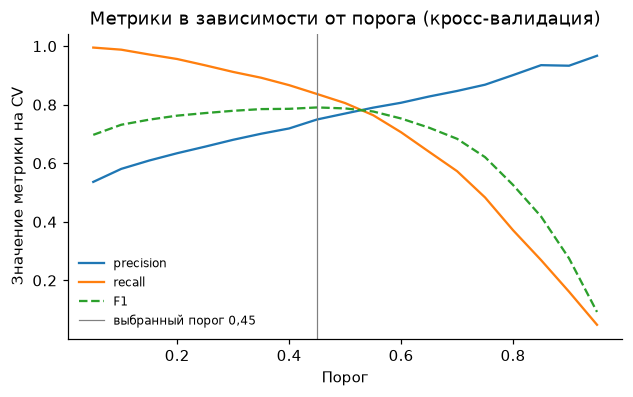

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(curve.index, curve["precision"], label="precision")
ax.plot(curve.index, curve["recall"], label="recall")
ax.plot(curve.index, curve["F1"], "--", label="F1")
ax.axvline(0.45, color="gray", lw=0.8, label="выбранный порог 0,45")
ax.set_xlabel("Порог")
ax.set_ylabel("Значение метрики на CV")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Метрики в зависимости от порога (кросс-валидация)")
plt.show()

**Вывод П3.**
- Порог выбран по вероятностям из `cross_val_predict` на обучающей выборке, тест для выбора не используется.
- С понижением порога recall растёт, precision падает. При 0,5 модель находит 80,6 % часов высокого спроса, при 0,45 уже 83,6 %, при 0,3 уже 91,2 %.
- Выбран порог 0,45. Пропуск дороже ложной тревоги, поэтому порог ниже 0,5. При этом 0,45 даёт лучший F1 на кросс-валидации (0,791), а precision остаётся 0,75: три предупреждения из четырёх верные. При 0,3 ложных тревог становится заметно больше, precision падает до 0,68, и F1 снижается до 0,779.
- Порог записан в `params_clf.json`, эксперимент `exp/threshold`.